In [1]:

from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print(f"- {filename}")


Saving loan_data.csv to loan_data.csv

Uploaded files:
- loan_data.csv


In [2]:

import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("loan_data.csv")

print("=" * 60)
print("LOANGUARD AI - INITIAL DATA INSPECTION")
print("=" * 60)

# Dataset dimensions
print("\n1. DATASET SHAPE")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

# Column names
print("\n2. COLUMN NAMES")
print(df.columns.tolist())

# First records
print("\n3. FIRST 5 RECORDS")
display(df.head())

# Data types and non-null counts
print("\n4. DATASET INFORMATION")
df.info()

# Missing values
print("\n5. MISSING VALUES")
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})
display(missing[missing["Missing Count"] > 0])

if df.isnull().sum().sum() == 0:
    print("No missing values found.")

# Duplicate records
print("\n6. DUPLICATE RECORDS")
print(f"Duplicate rows: {df.duplicated().sum():,}")

# Numerical summary
print("\n7. NUMERICAL FEATURES SUMMARY")
display(df.describe().T)

# Potential target inspection
print("\n8. TARGET COLUMN INSPECTION")

if "loan_status" in df.columns:
    print("Target column: loan_status")
    print("\nTarget distribution:")
    display(df["loan_status"].value_counts(dropna=False).to_frame("Count"))

    print("\nTarget distribution (%):")
    display(
        (df["loan_status"].value_counts(normalize=True, dropna=False) * 100)
        .round(2).to_frame("Percentage")
    )
else:
    print("Column 'loan_status' was not found.")
    print("We will identify the correct target after inspecting the columns.")

print("\n" + "=" * 60)
print("INITIAL INSPECTION COMPLETED")
print("=" * 60)


LOANGUARD AI - INITIAL DATA INSPECTION

1. DATASET SHAPE
Rows: 45,000
Columns: 14

2. COLUMN NAMES
['person_age', 'person_gender', 'person_education', 'person_income', 'person_emp_exp', 'person_home_ownership', 'loan_amnt', 'loan_intent', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score', 'previous_loan_defaults_on_file', 'loan_status']

3. FIRST 5 RECORDS


,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1



4. DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  object 
 2   person_education                45000 non-null  object 
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  object 
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  object 
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous

,Missing Count,Missing Percentage


No missing values found.

6. DUPLICATE RECORDS
Duplicate rows: 0

7. NUMERICAL FEATURES SUMMARY


,count,mean,std,min,25%,50%,75%,max
person_age,45000.0,27.764178,6.045108,20.00,24.00,26.00,30.00,144.00
person_income,45000.0,80319.053222,80422.498632,8000.00,47204.00,67048.00,95789.25,7200766.00
person_emp_exp,45000.0,5.410333,6.063532,0.00,1.00,4.00,8.00,125.00
loan_amnt,45000.0,9583.157556,6314.886691,500.00,5000.00,8000.00,12237.25,35000.00
loan_int_rate,45000.0,11.006606,2.978808,5.42,8.59,11.01,12.99,20.00
loan_percent_income,45000.0,0.139725,0.087212,0.00,0.07,0.12,0.19,0.66
cb_person_cred_hist_length,45000.0,5.867489,3.879702,2.00,3.00,4.00,8.00,30.00
credit_score,45000.0,632.608756,50.435865,390.00,601.00,640.00,670.00,850.00
loan_status,45000.0,0.222222,0.415744,0.00,0.00,0.00,0.00,1.00



8. TARGET COLUMN INSPECTION
Target column: loan_status

Target distribution:


,Count
loan_status,
0,35000
1,10000



Target distribution (%):


,Percentage
loan_status,
0,77.78
1,22.22



INITIAL INSPECTION COMPLETED


In [3]:

# ==========================================
# LOANGUARD AI - DATA QUALITY ASSESSMENT
# ==========================================

print("=" * 65)
print("DATA QUALITY ASSESSMENT")
print("=" * 65)

# 1. Categorical Features
categorical_columns = df.select_dtypes(include="object").columns

print("\n1. CATEGORICAL FEATURES")

for column in categorical_columns:
    print(f"\n{column}")
    print(f"Unique values: {df[column].nunique()}")
    print(df[column].value_counts(dropna=False))

# 2. Target Validation
print("\n2. TARGET VALIDATION")

print("Unique target values:", sorted(df["loan_status"].unique()))
print("Target data type:", df["loan_status"].dtype)

# 3. Potential Invalid Numerical Values
print("\n3. POTENTIAL INVALID VALUES")

quality_checks = {
    "Age below 18": df["person_age"] < 18,
    "Age above 100": df["person_age"] > 100,
    "Negative income": df["person_income"] < 0,
    "Zero income": df["person_income"] == 0,
    "Negative employment experience": df["person_emp_exp"] < 0,
    "Employment experience greater than age": (
        df["person_emp_exp"] > df["person_age"]
    ),
    "Non-positive loan amount": df["loan_amnt"] <= 0,
    "Non-positive interest rate": df["loan_int_rate"] <= 0,
    "Negative loan-to-income ratio": df["loan_percent_income"] < 0,
    "Loan-to-income ratio above 1": df["loan_percent_income"] > 1,
    "Negative credit history length": (
        df["cb_person_cred_hist_length"] < 0
    ),
    "Credit score outside 300-850": (
        (df["credit_score"] < 300) |
        (df["credit_score"] > 850)
    )
}

for issue, condition in quality_checks.items():
    count = condition.sum()
    print(f"{issue}: {count:,} ({count / len(df) * 100:.2f}%)")

# 4. Check Employment Experience vs Age
print("\n4. AGE AND EMPLOYMENT EXPERIENCE")

display(
    df.loc[
        df["person_emp_exp"] > df["person_age"],
        ["person_age", "person_emp_exp"]
    ].head(10)
)

# 5. Check Loan-to-Income Consistency
print("\n5. LOAN-TO-INCOME CONSISTENCY")

calculated_ratio = df["loan_amnt"] / df["person_income"]

ratio_difference = (
    df["loan_percent_income"] - calculated_ratio
).abs()

print("Mean absolute difference:",
      round(ratio_difference.mean(), 6))

print("Maximum absolute difference:",
      round(ratio_difference.max(), 6))

print("Rows with difference above 0.01:",
      (ratio_difference > 0.01).sum())

# 6. Numerical Outlier Investigation
print("\n6. EXTREME NUMERICAL VALUES")

columns_to_check = [
    "person_age",
    "person_income",
    "person_emp_exp",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
    "credit_score"
]

display(
    df[columns_to_check].quantile(
        [0, 0.01, 0.05, 0.95, 0.99, 1]
    ).T
)

print("\n" + "=" * 65)
print("DATA QUALITY ASSESSMENT COMPLETED")
print("=" * 65)


DATA QUALITY ASSESSMENT

1. CATEGORICAL FEATURES

person_gender
Unique values: 2
person_gender
male      24841
female    20159
Name: count, dtype: int64

person_education
Unique values: 5
person_education
Bachelor       13399
Associate      12028
High School    11972
Master          6980
Doctorate        621
Name: count, dtype: int64

person_home_ownership
Unique values: 4
person_home_ownership
RENT        23443
MORTGAGE    18489
OWN          2951
OTHER         117
Name: count, dtype: int64

loan_intent
Unique values: 6
loan_intent
EDUCATION            9153
MEDICAL              8548
VENTURE              7819
PERSONAL             7552
DEBTCONSOLIDATION    7145
HOMEIMPROVEMENT      4783
Name: count, dtype: int64

previous_loan_defaults_on_file
Unique values: 2
previous_loan_defaults_on_file
Yes    22858
No     22142
Name: count, dtype: int64

2. TARGET VALIDATION
Unique target values: [np.int64(0), np.int64(1)]
Target data type: int64

3. POTENTIAL INVALID VALUES
Age below 18: 0 (0.00%)


,person_age,person_emp_exp



5. LOAN-TO-INCOME CONSISTENCY
Mean absolute difference: 0.002525
Maximum absolute difference: 0.00503
Rows with difference above 0.01: 0

6. EXTREME NUMERICAL VALUES


,0.00,0.01,0.05,0.95,0.99,1.00
person_age,20.00,21.00,22.00,39.00,48.00,144.00
person_income,8000.00,17875.95,28366.70,166754.70,271450.06,7200766.00
person_emp_exp,0.00,0.00,0.00,17.00,26.00,125.00
loan_amnt,500.00,1138.87,2000.00,24000.00,28390.34,35000.00
loan_int_rate,5.42,5.42,6.17,16.00,18.25,20.00
loan_percent_income,0.00,0.02,0.03,0.31,0.40,0.66
cb_person_cred_hist_length,2.00,2.00,2.00,14.00,17.00,30.00
credit_score,390.00,497.00,539.00,703.00,724.00,850.00



DATA QUALITY ASSESSMENT COMPLETED


In [4]:

# ==========================================
# LOANGUARD AI - EXTREME VALUE INVESTIGATION
# ==========================================

print("=" * 65)
print("EXTREME VALUE INVESTIGATION")
print("=" * 65)

# 1. Applicants older than 100
print("\n1. APPLICANTS OLDER THAN 100")

old_applicants = df[df["person_age"] > 100]

display(
    old_applicants.sort_values(
        "person_age", ascending=False
    )
)

# 2. Highest income records
print("\n2. TOP 10 HIGHEST INCOME RECORDS")

display(
    df.nlargest(10, "person_income")[
        [
            "person_age",
            "person_income",
            "person_emp_exp",
            "loan_amnt",
            "loan_percent_income",
            "credit_score",
            "loan_status"
        ]
    ]
)

# 3. Highest employment experience
print("\n3. TOP 10 EMPLOYMENT EXPERIENCE RECORDS")

display(
    df.nlargest(10, "person_emp_exp")[
        [
            "person_age",
            "person_emp_exp",
            "person_income",
            "loan_amnt",
            "loan_status"
        ]
    ]
)

# 4. Check unusually high income values
print("\n4. HIGH INCOME DISTRIBUTION")

for threshold in [250000, 500000, 1000000]:
    count = (df["person_income"] > threshold).sum()

    print(
        f"Income > {threshold:,}: "
        f"{count:,} records "
        f"({count / len(df) * 100:.3f}%)"
    )

# 5. Check unusually high employment experience
print("\n5. HIGH EMPLOYMENT EXPERIENCE")

for threshold in [30, 40, 50]:
    count = (df["person_emp_exp"] > threshold).sum()

    print(
        f"Experience > {threshold} years: "
        f"{count:,} records "
        f"({count / len(df) * 100:.3f}%)"
    )

print("\n" + "=" * 65)
print("INVESTIGATION COMPLETED")
print("=" * 65)


EXTREME VALUE INVESTIGATION

1. APPLICANTS OLDER THAN 100


,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
81,144.0,male,Bachelor,300616.0,125,RENT,4800.0,VENTURE,13.57,0.02,3.0,789,No,0
183,144.0,male,Associate,241424.0,121,MORTGAGE,6000.0,EDUCATION,11.86,0.02,2.0,807,No,0
32297,144.0,female,Associate,7200766.0,124,MORTGAGE,5000.0,PERSONAL,12.73,0.00,25.0,850,No,0
575,123.0,female,High School,97140.0,101,RENT,20400.0,EDUCATION,10.25,0.21,3.0,805,Yes,0
747,123.0,male,Bachelor,94723.0,100,RENT,20000.0,VENTURE,11.01,0.21,4.0,714,Yes,0
37930,116.0,male,Bachelor,5545545.0,93,MORTGAGE,3823.0,VENTURE,12.15,0.00,24.0,708,No,0
38113,109.0,male,High School,5556399.0,85,MORTGAGE,6195.0,VENTURE,12.58,0.00,22.0,792,No,0



2. TOP 10 HIGHEST INCOME RECORDS


,person_age,person_income,person_emp_exp,loan_amnt,loan_percent_income,credit_score,loan_status
32297,144.0,7200766.0,124,5000.0,0.00,850,0
38113,109.0,5556399.0,85,6195.0,0.00,792,0
37930,116.0,5545545.0,93,3823.0,0.00,708,0
30049,42.0,2448661.0,16,8450.0,0.00,635,0
32546,60.0,2280980.0,37,1500.0,0.00,682,0
32497,63.0,2139143.0,43,12025.0,0.01,724,0
37175,42.0,2012954.0,19,9121.0,0.00,664,0
41288,46.0,1741243.0,22,12011.0,0.01,655,0
31924,44.0,1728974.0,20,6400.0,0.00,573,0
35850,47.0,1661567.0,22,6545.0,0.00,622,0



3. TOP 10 EMPLOYMENT EXPERIENCE RECORDS


,person_age,person_emp_exp,person_income,loan_amnt,loan_status
81,144.0,125,300616.0,4800.0,0
32297,144.0,124,7200766.0,5000.0,0
183,144.0,121,241424.0,6000.0,0
575,123.0,101,97140.0,20400.0,0
747,123.0,100,94723.0,20000.0,0
37930,116.0,93,5545545.0,3823.0,0
38113,109.0,85,5556399.0,6195.0,0
32416,94.0,76,29738.0,6500.0,0
32422,80.0,62,77894.0,6800.0,0
32506,84.0,61,114705.0,10000.0,0



4. HIGH INCOME DISTRIBUTION
Income > 250,000: 576 records (1.280%)
Income > 500,000: 104 records (0.231%)
Income > 1,000,000: 24 records (0.053%)

5. HIGH EMPLOYMENT EXPERIENCE
Experience > 30 years: 232 records (0.516%)
Experience > 40 years: 65 records (0.144%)
Experience > 50 years: 12 records (0.027%)

INVESTIGATION COMPLETED


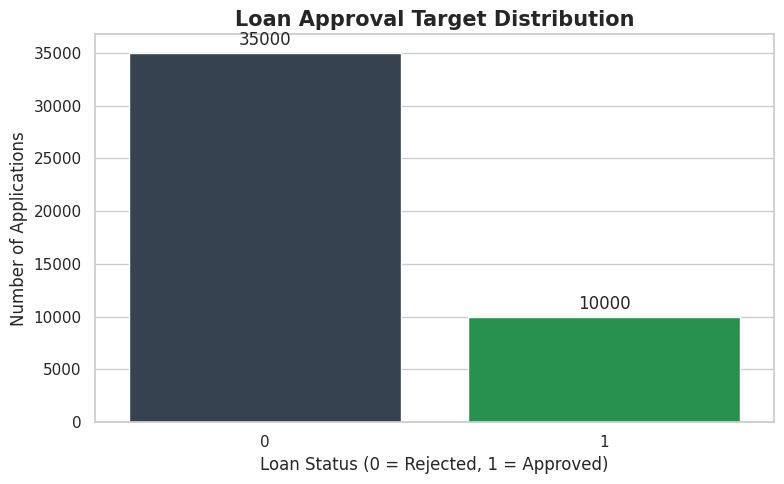

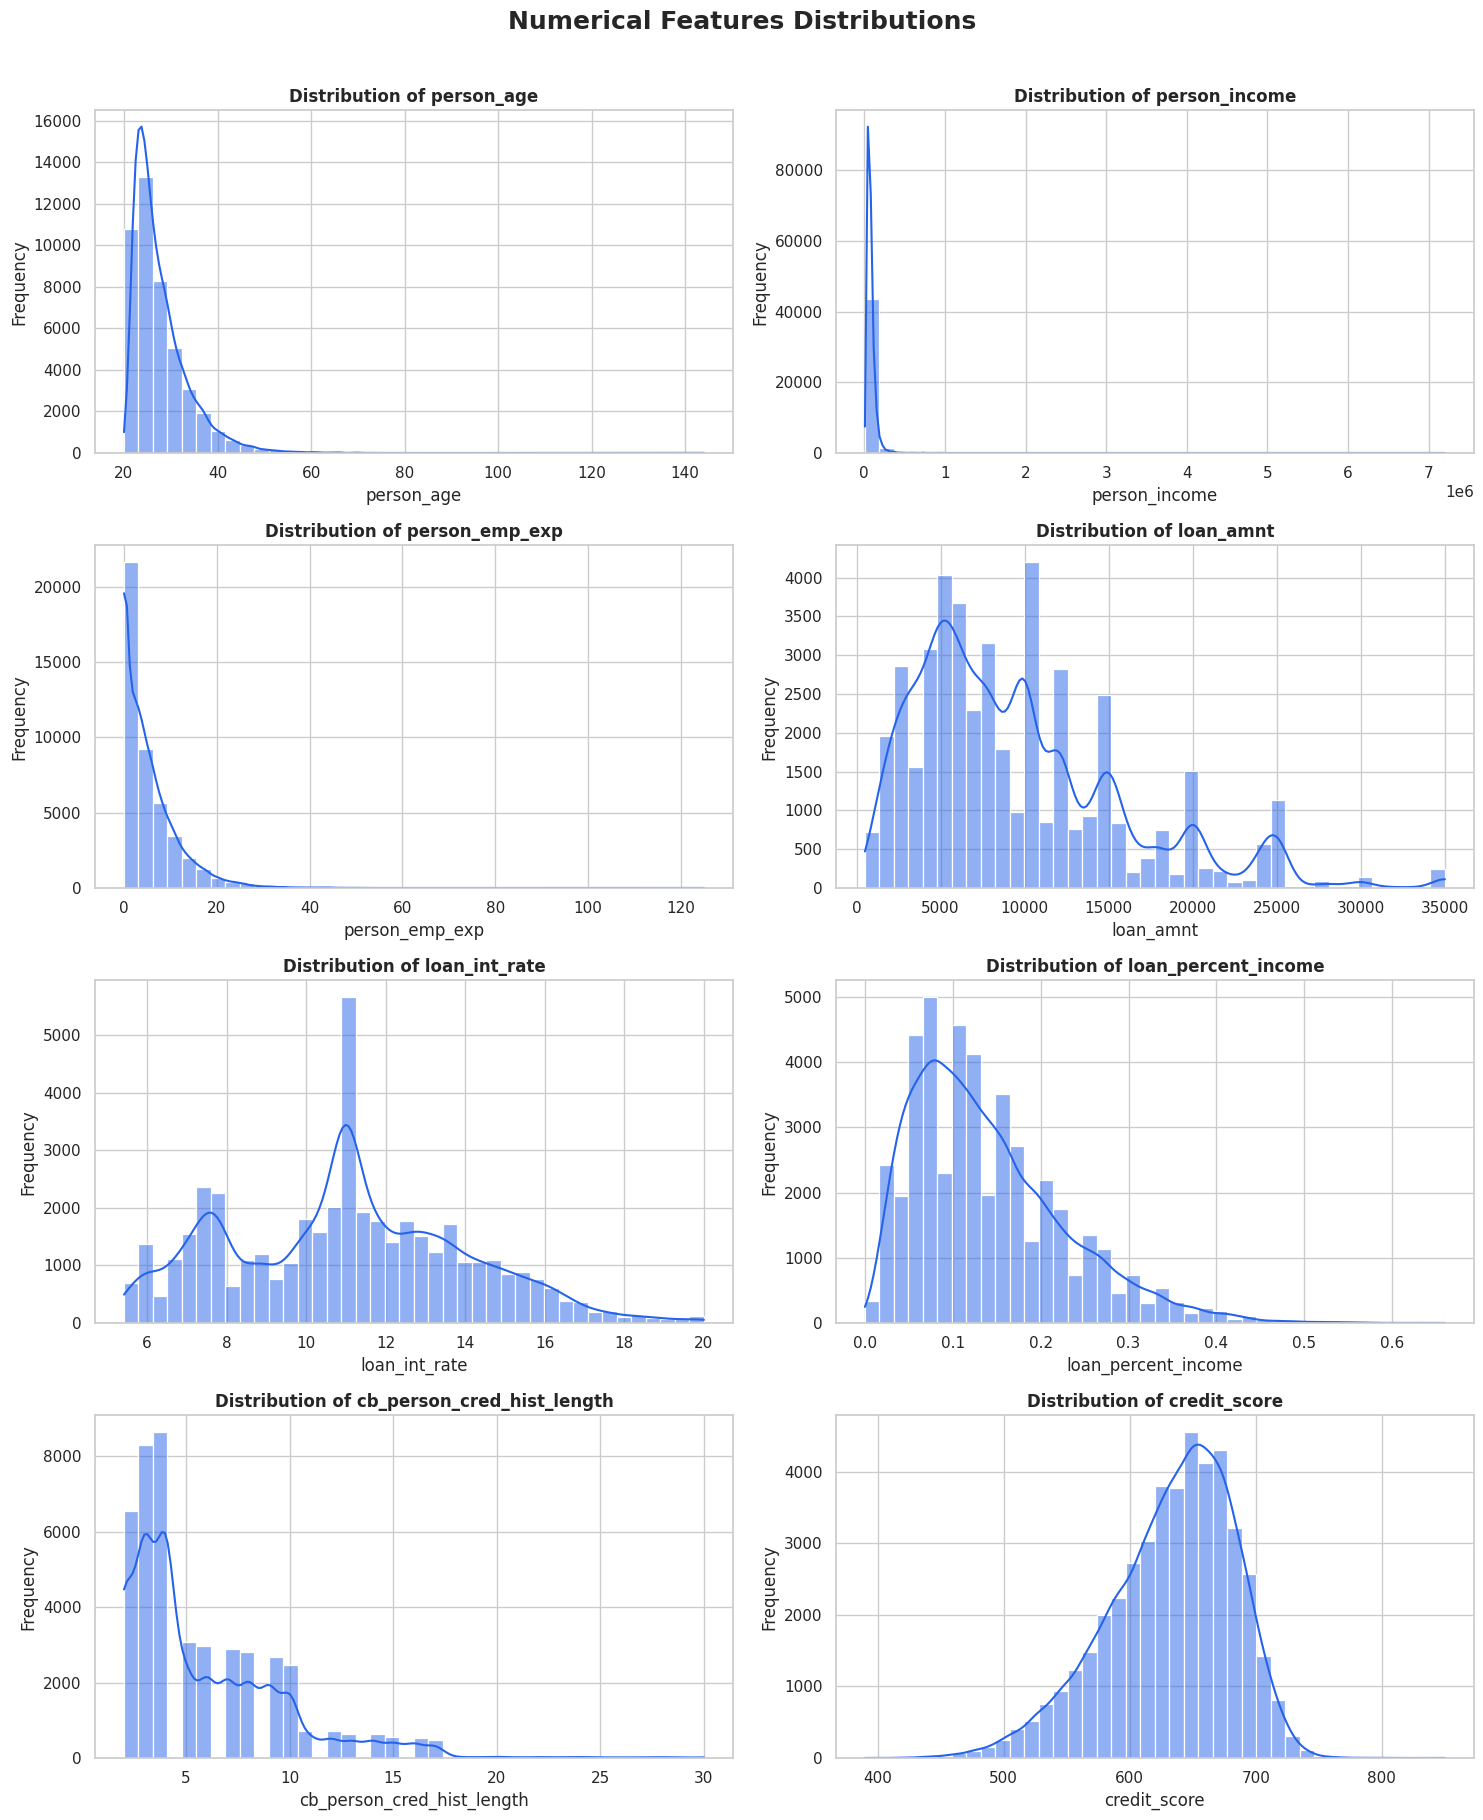

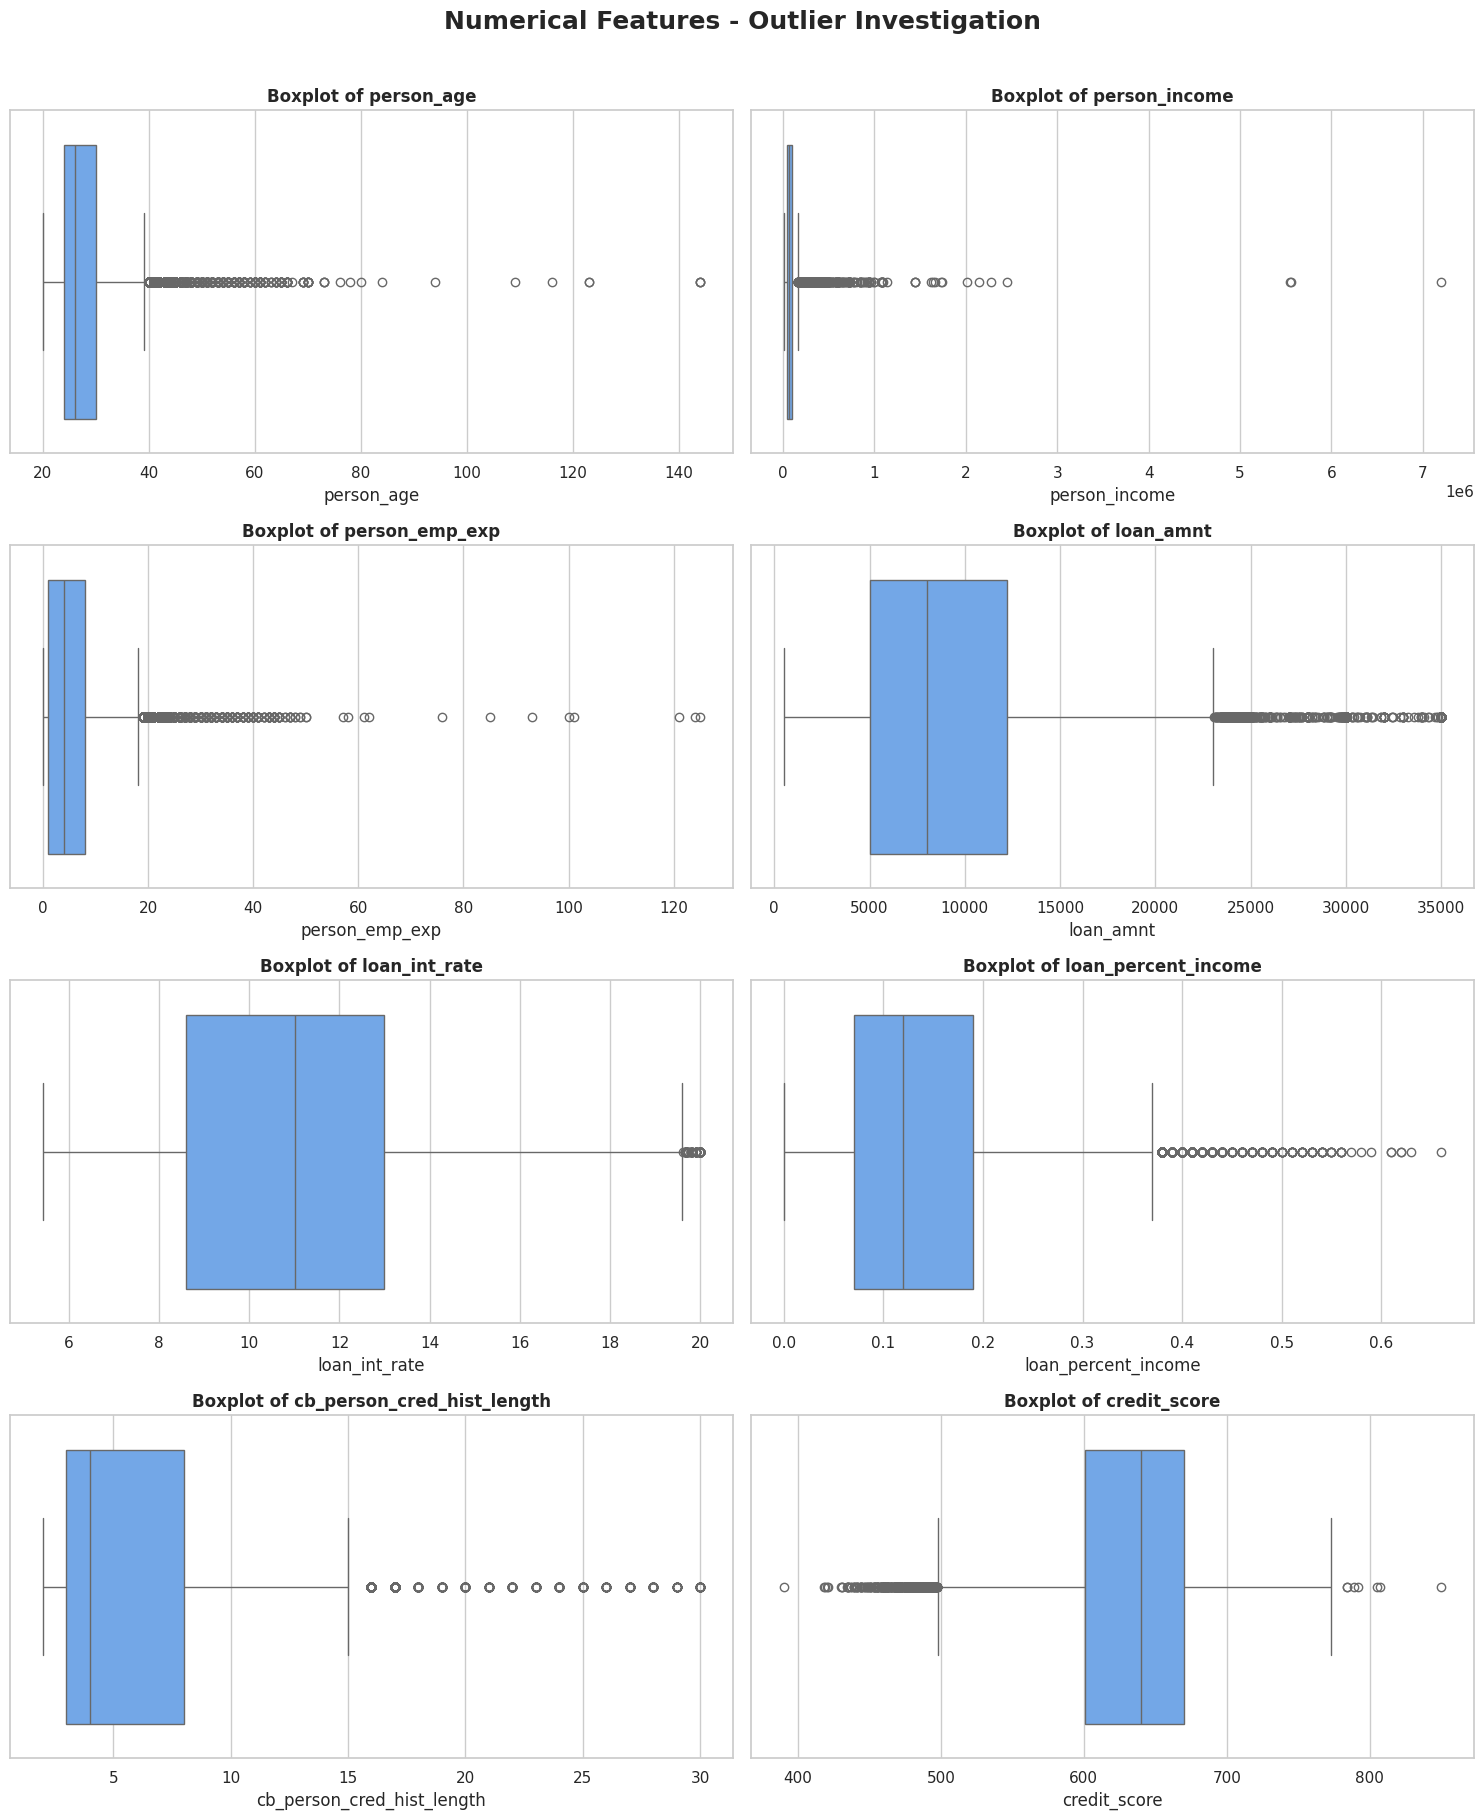

EDA Part 1 completed successfully.


In [5]:

# ==========================================
# LOANGUARD AI - EDA PART 1
# Numerical Features Distribution
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

# Numerical features excluding target
numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.drop("loan_status").tolist()

# 1. Target Distribution
fig, ax = plt.subplots(figsize=(8, 5))

target_counts = df["loan_status"].value_counts().sort_index()

sns.countplot(
    data=df,
    x="loan_status",
    hue="loan_status",
    order=[0, 1],
    palette=["#334155", "#16A34A"],
    legend=False,
    ax=ax
)

ax.set_title("Loan Approval Target Distribution",
             fontsize=15, fontweight="bold")
ax.set_xlabel("Loan Status (0 = Rejected, 1 = Approved)")
ax.set_ylabel("Number of Applications")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

# 2. Numerical Feature Histograms
fig, axes = plt.subplots(4, 2, figsize=(15, 18))

for ax, column in zip(axes.flatten(), numerical_features):

    sns.histplot(
        data=df,
        x=column,
        bins=40,
        kde=True,
        color="#2563EB",
        ax=ax
    )

    ax.set_title(f"Distribution of {column}", fontweight="bold")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")

plt.suptitle(
    "Numerical Features Distributions",
    fontsize=18,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

# 3. Numerical Feature Boxplots
fig, axes = plt.subplots(4, 2, figsize=(15, 18))

for ax, column in zip(axes.flatten(), numerical_features):

    sns.boxplot(
        data=df,
        x=column,
        color="#60A5FA",
        ax=ax
    )

    ax.set_title(f"Boxplot of {column}", fontweight="bold")
    ax.set_xlabel(column)

plt.suptitle(
    "Numerical Features - Outlier Investigation",
    fontsize=18,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

print("EDA Part 1 completed successfully.")


In [6]:

# ==========================================
# LOANGUARD AI - EDA NUMERICAL REPORT
# ==========================================

from scipy.stats import skew

print("=" * 75)
print("NUMERICAL FEATURES ANALYSIS REPORT")
print("=" * 75)

for column in numerical_features:

    series = df[column]

    skewness = skew(series, nan_policy="omit")

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (series < lower_bound) |
        (series > upper_bound)
    )

    outlier_count = outliers.sum()
    outlier_percentage = outlier_count / len(df) * 100

    if abs(skewness) < 0.5:
        distribution = "Approximately symmetric"
    elif skewness >= 0.5:
        distribution = "Right-skewed"
    else:
        distribution = "Left-skewed"

    print(f"\nFeature: {column}")
    print("-" * 50)
    print(f"Mean: {series.mean():,.3f}")
    print(f"Median: {series.median():,.3f}")
    print(f"Skewness: {skewness:.3f}")
    print(f"Distribution: {distribution}")
    print(f"IQR Lower Bound: {lower_bound:,.3f}")
    print(f"IQR Upper Bound: {upper_bound:,.3f}")
    print(f"Potential Outliers: {outlier_count:,}")
    print(f"Outlier Percentage: {outlier_percentage:.2f}%")

# ==========================================
# TARGET IMBALANCE REPORT
# ==========================================

print("\n" + "=" * 75)
print("TARGET IMBALANCE REPORT")
print("=" * 75)

target_distribution = df["loan_status"].value_counts(normalize=True) * 100

for label, percentage in target_distribution.items():
    class_name = "Approved" if label == 1 else "Rejected"
    print(f"{class_name} ({label}): {percentage:.2f}%")

print("\n" + "=" * 75)
print("EDA NUMERICAL ANALYSIS COMPLETED")
print("=" * 75)


NUMERICAL FEATURES ANALYSIS REPORT

Feature: person_age
--------------------------------------------------
Mean: 27.764
Median: 26.000
Skewness: 2.548
Distribution: Right-skewed
IQR Lower Bound: 15.000
IQR Upper Bound: 39.000
Potential Outliers: 2,188
Outlier Percentage: 4.86%

Feature: person_income
--------------------------------------------------
Mean: 80,319.053
Median: 67,048.000
Skewness: 34.136
Distribution: Right-skewed
IQR Lower Bound: -25,673.875
IQR Upper Bound: 168,667.125
Potential Outliers: 2,218
Outlier Percentage: 4.93%

Feature: person_emp_exp
--------------------------------------------------
Mean: 5.410
Median: 4.000
Skewness: 2.595
Distribution: Right-skewed
IQR Lower Bound: -9.500
IQR Upper Bound: 18.500
Potential Outliers: 1,724
Outlier Percentage: 3.83%

Feature: loan_amnt
--------------------------------------------------
Mean: 9,583.158
Median: 8,000.000
Skewness: 1.180
Distribution: Right-skewed
IQR Lower Bound: -5,855.875
IQR Upper Bound: 23,093.125
Potentia

In [7]:

# ==========================================
# LOANGUARD AI - FEATURE vs TARGET ANALYSIS
# ==========================================

import pandas as pd

print("=" * 75)
print("NUMERICAL FEATURES BY LOAN STATUS")
print("=" * 75)

numerical_analysis = [
    "person_age",
    "person_income",
    "person_emp_exp",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
    "credit_score"
]

grouped = df.groupby("loan_status")[numerical_analysis].agg(
    ["mean", "median"]
).round(2)

print(grouped.to_string())

# ==========================================
# CATEGORICAL FEATURES vs TARGET
# ==========================================

categorical_features = df.select_dtypes(
    include=["object"]
).columns.tolist()

print("\n" + "=" * 75)
print("APPROVAL RATE BY CATEGORICAL FEATURES")
print("=" * 75)

for column in categorical_features:

    summary = (
        df.groupby(column, dropna=False)["loan_status"]
        .agg(
            applications="count",
            approvals="sum",
            approval_rate="mean"
        )
        .sort_values("approval_rate", ascending=False)
    )

    summary["approval_rate"] = (
        summary["approval_rate"] * 100
    ).round(2)

    print(f"\nFeature: {column}")
    print("-" * 60)
    print(summary.to_string())

print("\n" + "=" * 75)
print("FEATURE vs TARGET ANALYSIS COMPLETED")
print("=" * 75)


NUMERICAL FEATURES BY LOAN STATUS
            person_age        person_income          person_emp_exp        loan_amnt         loan_int_rate        loan_percent_income        cb_person_cred_hist_length        credit_score       
                  mean median          mean   median           mean median      mean  median          mean median                mean median                       mean median         mean median
loan_status                                                                                                                                                                                       
0                27.83   26.0      86157.04  72928.0           5.48    4.0   9219.58  8000.0         10.48  10.85                0.12   0.11                       5.90    4.0       632.81  640.0
1                27.52   26.0      59886.10  50629.0           5.18    3.0  10855.69  9750.0         12.86  12.98                0.20   0.20                       5.76    4.0       631.8

In [8]:

# ==========================================
# LOANGUARD AI - DATA LEAKAGE INVESTIGATION
# ==========================================

print("=" * 75)
print("1. PREVIOUS DEFAULTS vs LOAN STATUS")
print("=" * 75)

defaults_target = pd.crosstab(
    df["previous_loan_defaults_on_file"],
    df["loan_status"],
    margins=True
)

print(defaults_target.to_string())

print("\nApproval rate by previous defaults:")
print(
    df.groupby("previous_loan_defaults_on_file")["loan_status"]
    .agg(["count", "mean"])
    .assign(approval_rate=lambda x: (x["mean"] * 100).round(2))
    .drop(columns="mean")
    .to_string()
)

# ==========================================
# 2. INTEREST RATE vs LOAN STATUS
# ==========================================

print("\n" + "=" * 75)
print("2. LOAN INTEREST RATE ANALYSIS")
print("=" * 75)

rate_analysis = df.groupby("loan_status")["loan_int_rate"].agg(
    ["count", "mean", "median", "min", "max", "std"]
).round(3)

print(rate_analysis.to_string())

# ==========================================
# 3. INTEREST RATE vs PREVIOUS DEFAULTS
# ==========================================

print("\n" + "=" * 75)
print("3. INTEREST RATE BY PREVIOUS DEFAULTS")
print("=" * 75)

print(
    df.groupby(
        ["previous_loan_defaults_on_file", "loan_status"]
    )["loan_int_rate"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(3)
    .to_string()
)

# ==========================================
# 4. TARGET VARIATION WITHIN EACH DEFAULT GROUP
# ==========================================

print("\n" + "=" * 75)
print("4. UNIQUE TARGET VALUES PER DEFAULT CATEGORY")
print("=" * 75)

print(
    df.groupby("previous_loan_defaults_on_file")["loan_status"]
    .nunique()
    .to_string()
)

print("\n" + "=" * 75)
print("DATA LEAKAGE INVESTIGATION COMPLETED")
print("=" * 75)


1. PREVIOUS DEFAULTS vs LOAN STATUS
loan_status                         0      1    All
previous_loan_defaults_on_file                     
No                              12142  10000  22142
Yes                             22858      0  22858
All                             35000  10000  45000

Approval rate by previous defaults:
                                count  approval_rate
previous_loan_defaults_on_file                      
No                              22142          45.16
Yes                             22858           0.00

2. LOAN INTEREST RATE ANALYSIS
             count    mean  median   min   max    std
loan_status                                          
0            35000  10.478   10.85  5.42  20.0  2.731
1            10000  12.857   12.98  5.42  20.0  3.069

3. INTEREST RATE BY PREVIOUS DEFAULTS
                                            count    mean  median   min   max
previous_loan_defaults_on_file loan_status                                   
No          

In [9]:

# ==========================================
# LOANGUARD AI - INITIAL DATA PREPARATION
# ==========================================

from sklearn.model_selection import train_test_split

# Create a separate modeling dataset
df_model = df.copy()

# Exclude interest rate under the pre-approval prediction assumption
excluded_features = ["loan_int_rate"]

# Separate features and target
X = df_model.drop(
    columns=["loan_status"] + excluded_features
)

y = df_model["loan_status"]

# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ==========================================
# SPLIT SUMMARY
# ==========================================

print("=" * 65)
print("LOANGUARD AI - DATA SPLIT SUMMARY")
print("=" * 65)

print(f"Original dataset: {df.shape}")
print(f"Features used: {X.shape[1]}")
print(f"Excluded features: {excluded_features}")

print(f"\nTraining features: {X_train.shape}")
print(f"Testing features:  {X_test.shape}")

print("\nTraining target distribution:")
print(
    y_train.value_counts()
    .rename(index={0: "Rejected", 1: "Approved"})
    .to_string()
)

print("\nTesting target distribution:")
print(
    y_test.value_counts()
    .rename(index={0: "Rejected", 1: "Approved"})
    .to_string()
)

print("\nTraining approval percentage:",
      round(y_train.mean() * 100, 2), "%")

print("Testing approval percentage:",
      round(y_test.mean() * 100, 2), "%")

print("\n" + "=" * 65)
print("INITIAL DATA SPLIT COMPLETED")
print("=" * 65)


LOANGUARD AI - DATA SPLIT SUMMARY
Original dataset: (45000, 14)
Features used: 12
Excluded features: ['loan_int_rate']

Training features: (36000, 12)
Testing features:  (9000, 12)

Training target distribution:
loan_status
Rejected    28000
Approved     8000

Testing target distribution:
loan_status
Rejected    7000
Approved    2000

Training approval percentage: 22.22 %
Testing approval percentage: 22.22 %

INITIAL DATA SPLIT COMPLETED


In [10]:

# ==========================================
# LOANGUARD AI - PREPROCESSING PIPELINE
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler

# Identify feature types
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data without fitting
X_test_processed = preprocessor.transform(X_test)

# ==========================================
# VALIDATION
# ==========================================

print("\n" + "=" * 65)
print("PREPROCESSING VALIDATION")
print("=" * 65)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nMissing values in training:", X_train.isnull().sum().sum())
print("Missing values in testing:", X_test.isnull().sum().sum())

print("\nPreprocessing fitted on training data only.")
print("Unknown test categories will be safely ignored.")

print("\n" + "=" * 65)
print("PREPROCESSING COMPLETED")
print("=" * 65)


Numerical features:
['person_age', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score']

Categorical features:
['person_gender', 'person_education', 'person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file']

PREPROCESSING VALIDATION
Original training shape: (36000, 12)
Processed training shape: (36000, 26)
Original testing shape: (9000, 12)
Processed testing shape: (9000, 26)

Missing values in training: 0
Missing values in testing: 0

Preprocessing fitted on training data only.
Unknown test categories will be safely ignored.

PREPROCESSING COMPLETED


In [11]:

# ==========================================
# LOANGUARD AI - BASELINE MODEL
# Logistic Regression
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Initialize model
baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train
baseline_model.fit(X_train_processed, y_train)

# Predictions
y_pred = baseline_model.predict(X_test_processed)
y_proba = baseline_model.predict_proba(X_test_processed)[:, 1]

# ==========================================
# EVALUATION
# ==========================================

print("=" * 70)
print("LOANGUARD AI - BASELINE MODEL EVALUATION")
print("=" * 70)

print(f"Accuracy:          {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision:         {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:            {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:          {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:           {roc_auc_score(y_test, y_proba):.4f}")
print(f"PR-AUC:            {average_precision_score(y_test, y_proba):.4f}")

print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("                 Predicted")
print("              Rejected  Approved")
print(f"Actual Rejected   {cm[0, 0]:5d}     {cm[0, 1]:5d}")
print(f"Actual Approved  {cm[1, 0]:5d}     {cm[1, 1]:5d}")

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Rejected", "Approved"],
        digits=4,
        zero_division=0
    )
)

print("=" * 70)
print("BASELINE TRAINING AND EVALUATION COMPLETED")
print("=" * 70)


LOANGUARD AI - BASELINE MODEL EVALUATION
Accuracy:          0.8709
Precision:         0.7346
Recall:            0.6560
F1-score:          0.6931
ROC-AUC:           0.9361
PR-AUC:            0.8148

CONFUSION MATRIX
                 Predicted
              Rejected  Approved
Actual Rejected    6526       474
Actual Approved    688      1312

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Rejected     0.9046    0.9323    0.9182      7000
    Approved     0.7346    0.6560    0.6931      2000

    accuracy                         0.8709      9000
   macro avg     0.8196    0.7941    0.8057      9000
weighted avg     0.8668    0.8709    0.8682      9000

BASELINE TRAINING AND EVALUATION COMPLETED


In [12]:

# ==========================================
# LOANGUARD AI - BALANCED LOGISTIC REGRESSION
# Validation Experiment
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Split the original training data into train and validation
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Create a fresh preprocessing pipeline
balanced_preprocessor = clone(preprocessor)

X_subtrain_processed = balanced_preprocessor.fit_transform(X_subtrain)
X_val_processed = balanced_preprocessor.transform(X_val)

# Initialize balanced Logistic Regression
balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train
balanced_model.fit(X_subtrain_processed, y_subtrain)

# Validation predictions
y_val_pred = balanced_model.predict(X_val_processed)
y_val_proba = balanced_model.predict_proba(X_val_processed)[:, 1]

# ==========================================
# VALIDATION EVALUATION
# ==========================================

print("=" * 70)
print("BALANCED LOGISTIC REGRESSION - VALIDATION RESULTS")
print("=" * 70)

print(f"Accuracy:          {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Precision:         {precision_score(y_val, y_val_pred, zero_division=0):.4f}")
print(f"Recall:            {recall_score(y_val, y_val_pred, zero_division=0):.4f}")
print(f"F1-score:          {f1_score(y_val, y_val_pred, zero_division=0):.4f}")
print(f"ROC-AUC:           {roc_auc_score(y_val, y_val_proba):.4f}")
print(f"PR-AUC:            {average_precision_score(y_val, y_val_proba):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred, labels=[0, 1]))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["Rejected", "Approved"],
        digits=4,
        zero_division=0
    )
)

print("=" * 70)
print("BALANCED VALIDATION EXPERIMENT COMPLETED")
print("=" * 70)


BALANCED LOGISTIC REGRESSION - VALIDATION RESULTS
Accuracy:          0.8131
Precision:         0.5476
Recall:            0.9131
F1-score:          0.6846
ROC-AUC:           0.9288
PR-AUC:            0.7908

Confusion Matrix:
[[4393 1207]
 [ 139 1461]]

Classification Report:
              precision    recall  f1-score   support

    Rejected     0.9693    0.7845    0.8672      5600
    Approved     0.5476    0.9131    0.6846      1600

    accuracy                         0.8131      7200
   macro avg     0.7585    0.8488    0.7759      7200
weighted avg     0.8756    0.8131    0.8266      7200

BALANCED VALIDATION EXPERIMENT COMPLETED


In [13]:

# ==========================================
# LOANGUARD AI - THRESHOLD TUNING
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Train regular Logistic Regression on the SAME subtrain split
regular_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

regular_model.fit(X_subtrain_processed, y_subtrain)

# Get probabilities from both models
regular_val_proba = regular_model.predict_proba(
    X_val_processed
)[:, 1]

balanced_val_proba = balanced_model.predict_proba(
    X_val_processed
)[:, 1]

# Evaluate different thresholds
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

results = []

# Regular model at default threshold
regular_pred = (regular_val_proba >= 0.50).astype(int)

results.append({
    "Model": "Regular Logistic Regression",
    "Threshold": 0.50,
    "Accuracy": accuracy_score(y_val, regular_pred),
    "Precision": precision_score(y_val, regular_pred, zero_division=0),
    "Recall": recall_score(y_val, regular_pred, zero_division=0),
    "F1": f1_score(y_val, regular_pred, zero_division=0)
})

# Balanced model at different thresholds
for threshold in thresholds:

    predictions = (
        balanced_val_proba >= threshold
    ).astype(int)

    results.append({
        "Model": "Balanced Logistic Regression",
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1": f1_score(y_val, predictions, zero_division=0)
    })

results_df = pd.DataFrame(results)

print("=" * 85)
print("VALIDATION THRESHOLD COMPARISON")
print("=" * 85)

print(
    results_df.round(4).to_string(index=False)
)

print("\n" + "=" * 85)
print("THRESHOLD EXPERIMENT COMPLETED")
print("=" * 85)


VALIDATION THRESHOLD COMPARISON
                       Model  Threshold  Accuracy  Precision  Recall     F1
 Regular Logistic Regression        0.5    0.8646     0.7160  0.6475 0.6800
Balanced Logistic Regression        0.3    0.7625     0.4831  0.9844 0.6481
Balanced Logistic Regression        0.4    0.7868     0.5108  0.9612 0.6671
Balanced Logistic Regression        0.5    0.8131     0.5476  0.9131 0.6846
Balanced Logistic Regression        0.6    0.8344     0.5892  0.8419 0.6933
Balanced Logistic Regression        0.7    0.8529     0.6461  0.7475 0.6931

THRESHOLD EXPERIMENT COMPLETED


In [14]:

# ==========================================
# LOANGUARD AI - TREE-BASED MODEL COMPARISON
# ==========================================

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

tree_results = []

for model_name, model in models.items():

    print(f"\nTraining {model_name}...")

    model.fit(X_subtrain_processed, y_subtrain)

    predictions = model.predict(X_val_processed)
    probabilities = model.predict_proba(X_val_processed)[:, 1]

    tree_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "PR-AUC": average_precision_score(y_val, probabilities)
    })

tree_results_df = pd.DataFrame(tree_results)

print("\n" + "=" * 90)
print("TREE-BASED MODELS - VALIDATION RESULTS")
print("=" * 90)

print(tree_results_df.round(4).to_string(index=False))

print("\n" + "=" * 90)
print("TREE-BASED MODEL COMPARISON COMPLETED")
print("=" * 90)



Training Random Forest...

Training Extra Trees...

TREE-BASED MODELS - VALIDATION RESULTS
        Model  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
Random Forest    0.8942     0.8401  0.6469 0.7309   0.9510  0.8683
  Extra Trees    0.8832     0.7940  0.6406 0.7091   0.9419  0.8437

TREE-BASED MODEL COMPARISON COMPLETED


In [15]:

# ==========================================
# LOANGUARD AI - RANDOM FOREST THRESHOLD TUNING
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

# Get probabilities from trained Random Forest
rf_model = models["Random Forest"]

rf_val_proba = rf_model.predict_proba(
    X_val_processed
)[:, 1]

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

rf_threshold_results = []

for threshold in thresholds:

    predictions = (
        rf_val_proba >= threshold
    ).astype(int)

    rf_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)

print("=" * 80)
print("RANDOM FOREST - THRESHOLD COMPARISON")
print("=" * 80)

print(rf_threshold_df.round(4).to_string(index=False))

# Best threshold based on F1
best_rf_row = rf_threshold_df.loc[
    rf_threshold_df["F1"].idxmax()
]

best_rf_threshold = float(best_rf_row["Threshold"])

best_rf_predictions = (
    rf_val_proba >= best_rf_threshold
).astype(int)

print("\nBest Threshold based on F1:")
print(best_rf_row.to_string())

print("\nConfusion Matrix at Best F1 Threshold:")
print(confusion_matrix(
    y_val,
    best_rf_predictions,
    labels=[0, 1]
))

print("\n" + "=" * 80)
print("RANDOM FOREST THRESHOLD TUNING COMPLETED")
print("=" * 80)


RANDOM FOREST - THRESHOLD COMPARISON
 Threshold  Accuracy  Precision  Recall     F1
       0.3    0.8653     0.6454  0.8738 0.7424
       0.4    0.8865     0.7366  0.7619 0.7490
       0.5    0.8942     0.8401  0.6469 0.7309
       0.6    0.8892     0.9160  0.5519 0.6888
       0.7    0.8828     0.9737  0.4856 0.6480

Best Threshold based on F1:
Threshold    0.400000
Accuracy     0.886528
Precision    0.736556
Recall       0.761875
F1           0.749002

Confusion Matrix at Best F1 Threshold:
[[5164  436]
 [ 381 1219]]

RANDOM FOREST THRESHOLD TUNING COMPLETED


In [16]:

# ==========================================
# LOANGUARD AI - RANDOM FOREST HYPERPARAMETER TUNING
# ==========================================

from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

from scipy.stats import randint

# Complete pipeline: preprocessing + Random Forest
rf_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# Hyperparameter search space
param_distributions = {
    "model__n_estimators": [200, 300, 400, 500],
    "model__max_depth": [None, 10, 15, 20, 25, 30],
    "model__min_samples_split": randint(2, 15),
    "model__min_samples_leaf": randint(1, 8),
    "model__max_features": ["sqrt", "log2", 0.7],
    "model__class_weight": [None, "balanced"]
}

# Stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Randomized search
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=12,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("Starting Random Forest hyperparameter search...")

rf_search.fit(X_subtrain, y_subtrain)

# Best model
best_rf_model = rf_search.best_estimator_

print("\n" + "=" * 75)
print("RANDOM FOREST - BEST HYPERPARAMETERS")
print("=" * 75)

print("Best CV PR-AUC:", round(rf_search.best_score_, 4))
print("\nBest Parameters:")

for parameter, value in rf_search.best_params_.items():
    print(f"{parameter}: {value}")

# Evaluate on validation set
best_rf_val_proba = best_rf_model.predict_proba(X_val)[:, 1]

# Evaluate at threshold 0.40 for comparison
threshold = 0.40
best_rf_val_pred = (
    best_rf_val_proba >= threshold
).astype(int)

print("\n" + "=" * 75)
print("TUNED RANDOM FOREST - VALIDATION RESULTS")
print("=" * 75)

print(f"Threshold:  {threshold:.2f}")
print(f"Accuracy:   {accuracy_score(y_val, best_rf_val_pred):.4f}")
print(f"Precision:  {precision_score(y_val, best_rf_val_pred, zero_division=0):.4f}")
print(f"Recall:     {recall_score(y_val, best_rf_val_pred, zero_division=0):.4f}")
print(f"F1-score:   {f1_score(y_val, best_rf_val_pred, zero_division=0):.4f}")
print(f"ROC-AUC:    {roc_auc_score(y_val, best_rf_val_proba):.4f}")
print(f"PR-AUC:     {average_precision_score(y_val, best_rf_val_proba):.4f}")

print("\n" + "=" * 75)
print("HYPERPARAMETER TUNING COMPLETED")
print("=" * 75)


Starting Random Forest hyperparameter search...
Fitting 3 folds for each of 12 candidates, totalling 36 fits

RANDOM FOREST - BEST HYPERPARAMETERS
Best CV PR-AUC: 0.8759

Best Parameters:
model__class_weight: None
model__max_depth: 25
model__max_features: 0.7
model__min_samples_leaf: 2
model__min_samples_split: 4
model__n_estimators: 400

TUNED RANDOM FOREST - VALIDATION RESULTS
Threshold:  0.40
Accuracy:   0.8958
Precision:  0.7601
Recall:     0.7762
F1-score:   0.7681
ROC-AUC:    0.9558
PR-AUC:     0.8792

HYPERPARAMETER TUNING COMPLETED


In [17]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

for threshold in thresholds:
    val_predictions = (
        best_rf_val_proba >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, val_predictions),
        "Precision": precision_score(y_val, val_predictions, zero_division=0),
        "Recall": recall_score(y_val, val_predictions, zero_division=0),
        "F1-score": f1_score(y_val, val_predictions, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

print("TUNED RANDOM FOREST - THRESHOLD COMPARISON")
print("=" * 75)

print(
    threshold_df.to_string(
        index=False,
        formatters={
            "Threshold": "{:.2f}".format,
            "Accuracy": "{:.4f}".format,
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1-score": "{:.4f}".format
        }
    )
)

best_threshold = threshold_df.loc[
    threshold_df["F1-score"].idxmax(), "Threshold"
]

print("\nBest Threshold by F1-score:", best_threshold)

TUNED RANDOM FOREST - THRESHOLD COMPARISON
Threshold Accuracy Precision Recall F1-score
     0.30   0.8771    0.6725 0.8712   0.7591
     0.35   0.8871    0.7128 0.8237   0.7643
     0.40   0.8958    0.7601 0.7762   0.7681
     0.45   0.8992    0.8006 0.7275   0.7623
     0.50   0.8994    0.8385 0.6781   0.7498
     0.55   0.8974    0.8773 0.6256   0.7304
     0.60   0.8928    0.9035 0.5794   0.7060
     0.65   0.8892    0.9239 0.5463   0.6866
     0.70   0.8868    0.9486 0.5188   0.6707

Best Threshold by F1-score: 0.4


In [18]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

FINAL_THRESHOLD = 0.40

# Use the tuned model selected through training and validation
final_test_proba = best_rf_model.predict_proba(X_test)[:, 1]

final_test_predictions = (
    final_test_proba >= FINAL_THRESHOLD
).astype(int)

print("=" * 75)
print("LOANGUARD AI - FINAL TEST EVALUATION")
print("=" * 75)

print(f"\nDecision Threshold: {FINAL_THRESHOLD:.2f}")

print("\nClassification Metrics")
print("-" * 45)

print(f"Accuracy:  {accuracy_score(y_test, final_test_predictions):.4f}")
print(f"Precision: {precision_score(y_test, final_test_predictions):.4f}")
print(f"Recall:    {recall_score(y_test, final_test_predictions):.4f}")
print(f"F1-score:  {f1_score(y_test, final_test_predictions):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, final_test_proba):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, final_test_proba):.4f}")

print("\nConfusion Matrix")
print("-" * 45)
print(confusion_matrix(y_test, final_test_predictions))

print("\nClassification Report")
print("-" * 45)
print(
    classification_report(
        y_test,
        final_test_predictions,
        target_names=["Rejected (0)", "Approved (1)"],
        digits=4
    )
)

print("=" * 75)
print("FINAL TEST EVALUATION COMPLETED")
print("=" * 75)

LOANGUARD AI - FINAL TEST EVALUATION

Decision Threshold: 0.40

Classification Metrics
---------------------------------------------
Accuracy:  0.8988
Precision: 0.7678
Recall:    0.7805
F1-score:  0.7741
ROC-AUC:   0.9578
PR-AUC:    0.8865

Confusion Matrix
---------------------------------------------
[[6528  472]
 [ 439 1561]]

Classification Report
---------------------------------------------
              precision    recall  f1-score   support

Rejected (0)     0.9370    0.9326    0.9348      7000
Approved (1)     0.7678    0.7805    0.7741      2000

    accuracy                         0.8988      9000
   macro avg     0.8524    0.8565    0.8544      9000
weighted avg     0.8994    0.8988    0.8991      9000

FINAL TEST EVALUATION COMPLETED


In [19]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

thresholds = np.arange(0.10, 0.701, 0.01)

results = []

for threshold in thresholds:
    predictions = (
        best_rf_val_proba >= threshold
    ).astype(int)

    precision = precision_score(
        y_val, predictions, zero_division=0
    )

    recall = recall_score(
        y_val, predictions, zero_division=0
    )

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1_score(y_val, predictions),
        "Accuracy": accuracy_score(y_val, predictions)
    })

threshold_results = pd.DataFrame(results)

# Thresholds achieving both targets
both_targets = threshold_results[
    (threshold_results["Precision"] >= 0.80) &
    (threshold_results["Recall"] >= 0.80)
]

print("=" * 75)
print("PRECISION & RECALL OPTIMIZATION")
print("=" * 75)

if not both_targets.empty:
    print("\nThresholds achieving BOTH Precision and Recall >= 80%:")
    print(
        both_targets.sort_values(
            "F1-score", ascending=False
        ).head(10).to_string(
            index=False,
            formatters={
                "Threshold": "{:.2f}".format,
                "Precision": "{:.4f}".format,
                "Recall": "{:.4f}".format,
                "F1-score": "{:.4f}".format,
                "Accuracy": "{:.4f}".format
            }
        )
    )
else:
    print("\nNo threshold achieved both targets.")

print("\nBest Precision among thresholds with Recall >= 80%:")
recall_candidates = threshold_results[
    threshold_results["Recall"] >= 0.80
]

if not recall_candidates.empty:
    print(
        recall_candidates.sort_values(
            "Precision", ascending=False
        ).head(5).to_string(index=False)
    )
else:
    print("No threshold achieved Recall >= 80%.")

print("\nBest Recall among thresholds with Precision >= 80%:")
precision_candidates = threshold_results[
    threshold_results["Precision"] >= 0.80
]

if not precision_candidates.empty:
    print(
        precision_candidates.sort_values(
            "Recall", ascending=False
        ).head(5).to_string(index=False)
    )
else:
    print("No threshold achieved Precision >= 80%.")

PRECISION & RECALL OPTIMIZATION

No threshold achieved both targets.

Best Precision among thresholds with Recall >= 80%:
 Threshold  Precision   Recall  F1-score  Accuracy
      0.37   0.727428 0.800625  0.762273  0.889028
      0.36   0.721638 0.815000  0.765483  0.889028
      0.35   0.712818 0.823750  0.764280  0.887083
      0.34   0.704953 0.836250  0.765009  0.885833
      0.33   0.696641 0.842500  0.762659  0.883472

Best Recall among thresholds with Precision >= 80%:
 Threshold  Precision   Recall  F1-score  Accuracy
      0.45   0.800550 0.727500  0.762279  0.899167
      0.46   0.809625 0.715000  0.759376  0.899306
      0.47   0.811416 0.701875  0.752681  0.897500
      0.48   0.822009 0.695625  0.753555  0.898889
      0.49   0.831061 0.685625  0.751370  0.899167


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

from xgboost import XGBClassifier

print("Training XGBoost model...")

xgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", XGBClassifier(
        n_estimators=400,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.85,
        colsample_bytree=0.85,
        min_child_weight=3,
        reg_lambda=2,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_pipeline.fit(X_subtrain, y_subtrain)

xgb_val_proba = xgb_pipeline.predict_proba(X_val)[:, 1]

print("\n" + "=" * 70)
print("XGBOOST - VALIDATION RESULTS")
print("=" * 70)

print(f"PR-AUC:  {average_precision_score(y_val, xgb_val_proba):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_val, xgb_val_proba):.4f}")

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

print("\nThreshold Comparison")
print("-" * 70)

for threshold in thresholds:
    predictions = (xgb_val_proba >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision_score(y_val, predictions):.4f} | "
        f"Recall: {recall_score(y_val, predictions):.4f} | "
        f"F1: {f1_score(y_val, predictions):.4f} | "
        f"Accuracy: {accuracy_score(y_val, predictions):.4f}"
    )

print("\nXGBOOST TRAINING COMPLETED")

Training XGBoost model...

XGBOOST - VALIDATION RESULTS
PR-AUC:  0.8870
ROC-AUC: 0.9592

Threshold Comparison
----------------------------------------------------------------------
Threshold: 0.30 | Precision: 0.6836 | Recall: 0.8669 | F1: 0.7644 | Accuracy: 0.8812
Threshold: 0.35 | Precision: 0.7269 | Recall: 0.8300 | F1: 0.7750 | Accuracy: 0.8929
Threshold: 0.40 | Precision: 0.7697 | Recall: 0.7856 | F1: 0.7776 | Accuracy: 0.9001
Threshold: 0.45 | Precision: 0.8079 | Recall: 0.7438 | F1: 0.7745 | Accuracy: 0.9038
Threshold: 0.50 | Precision: 0.8421 | Recall: 0.6931 | F1: 0.7604 | Accuracy: 0.9029
Threshold: 0.55 | Precision: 0.8732 | Recall: 0.6500 | F1: 0.7453 | Accuracy: 0.9012
Threshold: 0.60 | Precision: 0.9009 | Recall: 0.6081 | F1: 0.7261 | Accuracy: 0.8981

XGBOOST TRAINING COMPLETED


In [21]:
import numpy as np

from scipy.stats import randint, uniform, loguniform
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from xgboost import XGBClassifier

print("Starting XGBoost hyperparameter optimization...")

xgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1,
        tree_method="hist"
    ))
])

param_distributions = {
    "model__n_estimators": randint(250, 801),
    "model__max_depth": randint(3, 9),
    "model__learning_rate": loguniform(0.01, 0.15),
    "model__subsample": uniform(0.65, 0.35),
    "model__colsample_bytree": uniform(0.65, 0.35),
    "model__min_child_weight": randint(1, 10),
    "model__gamma": uniform(0, 3),
    "model__reg_lambda": loguniform(0.5, 10),
    "model__scale_pos_weight": [1, 1.5, 2, 2.5, 3]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

xgb_search.fit(X_subtrain, y_subtrain)

best_xgb_model = xgb_search.best_estimator_

best_xgb_val_proba = best_xgb_model.predict_proba(X_val)[:, 1]

print("\n" + "=" * 70)
print("TUNED XGBOOST - BEST HYPERPARAMETERS")
print("=" * 70)

print(f"Best CV PR-AUC: {xgb_search.best_score_:.4f}")

for parameter, value in xgb_search.best_params_.items():
    print(f"{parameter}: {value}")

print("\nVALIDATION PERFORMANCE")
print("-" * 70)

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

print(
    f"Validation PR-AUC: "
    f"{average_precision_score(y_val, best_xgb_val_proba):.4f}"
)

print(
    f"Validation ROC-AUC: "
    f"{roc_auc_score(y_val, best_xgb_val_proba):.4f}"
)

print("\nXGBOOST HYPERPARAMETER SEARCH COMPLETED")

Starting XGBoost hyperparameter optimization...
Fitting 3 folds for each of 20 candidates, totalling 60 fits

TUNED XGBOOST - BEST HYPERPARAMETERS
Best CV PR-AUC: 0.8879
model__colsample_bytree: 0.8891422315889104
model__gamma: 1.8299899733478626
model__learning_rate: 0.0954801852130355
model__max_depth: 5
model__min_child_weight: 1
model__n_estimators: 637
model__reg_lambda: 1.272083045469184
model__scale_pos_weight: 1.5
model__subsample: 0.848695114736997

VALIDATION PERFORMANCE
----------------------------------------------------------------------
Validation PR-AUC: 0.8894
Validation ROC-AUC: 0.9602

XGBOOST HYPERPARAMETER SEARCH COMPLETED


In [22]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(0.10, 0.701, 0.01)

results = []

for threshold in thresholds:
    predictions = (
        best_xgb_val_proba >= threshold
    ).astype(int)

    precision = precision_score(
        y_val, predictions, zero_division=0
    )

    recall = recall_score(
        y_val, predictions, zero_division=0
    )

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1_score(y_val, predictions),
        "Accuracy": accuracy_score(y_val, predictions)
    })

xgb_threshold_df = pd.DataFrame(results)

both_targets = xgb_threshold_df[
    (xgb_threshold_df["Precision"] >= 0.80) &
    (xgb_threshold_df["Recall"] >= 0.80)
]

print("=" * 75)
print("TUNED XGBOOST - PRECISION & RECALL OPTIMIZATION")
print("=" * 75)

if not both_targets.empty:
    print("\nThresholds achieving BOTH targets:")
    print(
        both_targets.sort_values(
            "F1-score", ascending=False
        ).head(10).to_string(index=False)
    )
else:
    print("\nNo threshold achieved both targets.")

print("\nBest Precision with Recall >= 80%:")
recall_candidates = xgb_threshold_df[
    xgb_threshold_df["Recall"] >= 0.80
]

if not recall_candidates.empty:
    print(
        recall_candidates.sort_values(
            "Precision", ascending=False
        ).head(5).to_string(index=False)
    )

print("\nBest Recall with Precision >= 80%:")
precision_candidates = xgb_threshold_df[
    xgb_threshold_df["Precision"] >= 0.80
]

if not precision_candidates.empty:
    print(
        precision_candidates.sort_values(
            "Recall", ascending=False
        ).head(5).to_string(index=False)
    )

print("\nBest F1-score:")
print(
    xgb_threshold_df.loc[
        xgb_threshold_df["F1-score"].idxmax()
    ].to_string()
)

TUNED XGBOOST - PRECISION & RECALL OPTIMIZATION

No threshold achieved both targets.

Best Precision with Recall >= 80%:
 Threshold  Precision   Recall  F1-score  Accuracy
      0.47   0.757059 0.804375  0.780000  0.899167
      0.46   0.750145 0.810625  0.779213  0.897917
      0.45   0.742027 0.814375  0.776520  0.895833
      0.44   0.734410 0.824375  0.776796  0.894722
      0.43   0.724646 0.830625  0.774024  0.892222

Best Recall with Precision >= 80%:
 Threshold  Precision   Recall  F1-score  Accuracy
      0.54   0.801603 0.750000  0.774943  0.903194
      0.55   0.809394 0.743125  0.774845  0.904028
      0.56   0.821229 0.735000  0.775726  0.905556
      0.57   0.830364 0.728125  0.775891  0.906528
      0.58   0.835149 0.718750  0.772590  0.905972

Best F1-score:
Threshold    0.470000
Precision    0.757059
Recall       0.804375
F1-score     0.780000
Accuracy     0.899167


In [24]:
import pandas as pd

from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

print("Restarting CatBoost optimization with valid parameters...")

catboost_model = CatBoostClassifier(
    loss_function="Logloss",
    eval_metric="PRAUC",
    random_seed=42,
    verbose=0,
    allow_writing_files=False,
    thread_count=1
)

param_distributions = {
    "iterations": [400, 600, 800, 1000],
    "depth": [4, 5, 6, 7, 8],
    "learning_rate": [0.02, 0.03, 0.05, 0.07, 0.1],
    "l2_leaf_reg": [3, 5, 7, 9],
    "random_strength": [0.5, 1, 2, 3],
    "auto_class_weights": ["Balanced", "SqrtBalanced"]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cat_search = RandomizedSearchCV(
    estimator=catboost_model,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True,
    error_score="raise"
)

cat_search.fit(
    X_subtrain,
    y_subtrain,
    cat_features=categorical_features
)

best_cat_model = cat_search.best_estimator_

cat_val_proba = best_cat_model.predict_proba(X_val)[:, 1]

print("\n" + "=" * 70)
print("CATBOOST - CORRECTED OPTIMIZATION")
print("=" * 70)

print(f"Best CV PR-AUC: {cat_search.best_score_:.4f}")
print(f"Validation PR-AUC: {average_precision_score(y_val, cat_val_proba):.4f}")
print(f"Validation ROC-AUC: {roc_auc_score(y_val, cat_val_proba):.4f}")

print("\nBest Parameters:")
for parameter, value in cat_search.best_params_.items():
    print(f"{parameter}: {value}")

print("\nCATBOOST OPTIMIZATION COMPLETED")

Restarting CatBoost optimization with valid parameters...
Fitting 3 folds for each of 15 candidates, totalling 45 fits

CATBOOST - CORRECTED OPTIMIZATION
Best CV PR-AUC: 0.8863
Validation PR-AUC: 0.8859
Validation ROC-AUC: 0.9585

Best Parameters:
random_strength: 3
learning_rate: 0.07
l2_leaf_reg: 7
iterations: 800
depth: 5
auto_class_weights: SqrtBalanced

CATBOOST OPTIMIZATION COMPLETED


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)
from xgboost import XGBClassifier
import pandas as pd

print("Starting corrected feature ablation experiment...")

# Best XGBoost parameters
xgb_params = {
    "n_estimators": 637,
    "max_depth": 5,
    "learning_rate": 0.0954801852130355,
    "subsample": 0.848695114736997,
    "colsample_bytree": 0.8891422315889104,
    "min_child_weight": 1,
    "gamma": 1.8299899733478626,
    "reg_lambda": 1.272083045469184,
    "scale_pos_weight": 1.5,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "random_state": 42,
    "n_jobs": -1,
    "tree_method": "hist"
}

feature_to_remove = "previous_loan_defaults_on_file"

# Prepare reduced datasets
X_subtrain_reduced = X_subtrain.drop(columns=[feature_to_remove])
X_val_reduced = X_val.drop(columns=[feature_to_remove])

# Rebuild preprocessing feature lists
reduced_numerical_features = [
    col for col in numerical_features
    if col in X_subtrain_reduced.columns
]

reduced_categorical_features = [
    col for col in categorical_features
    if col in X_subtrain_reduced.columns
]

# Build a new preprocessor for the reduced dataset
reduced_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            clone(numerical_transformer),
            reduced_numerical_features
        ),
        (
            "cat",
            clone(categorical_transformer),
            reduced_categorical_features
        )
    ],
    remainder="drop"
)

# Model 1: With all features
full_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", XGBClassifier(**xgb_params))
])

full_model.fit(X_subtrain, y_subtrain)
full_proba = full_model.predict_proba(X_val)[:, 1]

# Model 2: Without previous loan defaults
reduced_model = Pipeline([
    ("preprocessor", reduced_preprocessor),
    ("model", XGBClassifier(**xgb_params))
])

reduced_model.fit(X_subtrain_reduced, y_subtrain)
reduced_proba = reduced_model.predict_proba(X_val_reduced)[:, 1]

# Evaluate both models at the same threshold
results = []

for name, probabilities in [
    ("With Previous Defaults", full_proba),
    ("Without Previous Defaults", reduced_proba)
]:
    predictions = (probabilities >= 0.40).astype(int)

    results.append({
        "Model": name,
        "PR-AUC": average_precision_score(y_val, probabilities),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1-score": f1_score(y_val, predictions)
    })

ablation_results = pd.DataFrame(results)

print("\n" + "=" * 85)
print("FEATURE ABLATION RESULTS")
print("=" * 85)

print(
    ablation_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nFEATURE ABLATION COMPLETED")

Starting corrected feature ablation experiment...

FEATURE ABLATION RESULTS
                    Model  PR-AUC  ROC-AUC  Precision  Recall  F1-score
   With Previous Defaults  0.8894   0.9602     0.7043  0.8469    0.7690
Without Previous Defaults  0.7983   0.8919     0.7397  0.6538    0.6941

FEATURE ABLATION COMPLETED


In [27]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

thresholds = np.arange(0.10, 0.801, 0.01)

results = []

for threshold in thresholds:
    predictions = (
        full_proba >= threshold
    ).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "Accuracy": accuracy_score(
            y_val, predictions
        )
    })

ablation_threshold_df = pd.DataFrame(results)

both_targets = ablation_threshold_df[
    (ablation_threshold_df["Precision"] >= 0.80) &
    (ablation_threshold_df["Recall"] >= 0.80)
]

print("=" * 75)
print("FULL XGBOOST - THRESHOLD OPTIMIZATION")
print("=" * 75)

if not both_targets.empty:
    print("\nThresholds achieving both targets:")
    print(
        both_targets.sort_values(
            "F1-score", ascending=False
        ).head(10).to_string(index=False)
    )
else:
    print("\nNo threshold achieved both targets.")

print("\nBest Precision with Recall >= 80%:")
recall_candidates = ablation_threshold_df[
    ablation_threshold_df["Recall"] >= 0.80
]

print(
    recall_candidates.sort_values(
        "Precision", ascending=False
    ).head(5).to_string(index=False)
)

print("\nBest Recall with Precision >= 80%:")
precision_candidates = ablation_threshold_df[
    ablation_threshold_df["Precision"] >= 0.80
]

print(
    precision_candidates.sort_values(
        "Recall", ascending=False
    ).head(5).to_string(index=False)
)

FULL XGBOOST - THRESHOLD OPTIMIZATION

No threshold achieved both targets.

Best Precision with Recall >= 80%:
 Threshold  Precision   Recall  F1-score  Accuracy
      0.47   0.757059 0.804375  0.780000  0.899167
      0.46   0.750145 0.810625  0.779213  0.897917
      0.45   0.742027 0.814375  0.776520  0.895833
      0.44   0.734410 0.824375  0.776796  0.894722
      0.43   0.724646 0.830625  0.774024  0.892222

Best Recall with Precision >= 80%:
 Threshold  Precision   Recall  F1-score  Accuracy
      0.54   0.801603 0.750000  0.774943  0.903194
      0.55   0.809394 0.743125  0.774845  0.904028
      0.56   0.821229 0.735000  0.775726  0.905556
      0.57   0.830364 0.728125  0.775891  0.906528
      0.58   0.835149 0.718750  0.772590  0.905972


In [28]:
from sklearn.inspection import permutation_importance
import pandas as pd

print("Calculating Permutation Feature Importance...")

importance_result = permutation_importance(
    full_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance Mean": importance_result.importances_mean,
    "Importance Std": importance_result.importances_std
})

feature_importance = feature_importance.sort_values(
    by="Importance Mean",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 75)
print("PERMUTATION FEATURE IMPORTANCE")
print("=" * 75)

print(
    feature_importance.to_string(
        index=False,
        formatters={
            "Importance Mean": "{:.5f}".format,
            "Importance Std": "{:.5f}".format
        }
    )
)

print("\nFEATURE IMPORTANCE ANALYSIS COMPLETED.")

Calculating Permutation Feature Importance...

PERMUTATION FEATURE IMPORTANCE
                       Feature Importance Mean Importance Std
previous_loan_defaults_on_file         0.37009        0.00749
           loan_percent_income         0.15606        0.00703
                 person_income         0.11071        0.00368
         person_home_ownership         0.11045        0.00439
                   loan_intent         0.04177        0.00176
                  credit_score         0.01829        0.00313
                     loan_amnt         0.00931        0.00028
                    person_age         0.00378        0.00138
    cb_person_cred_hist_length         0.00262        0.00099
                person_emp_exp         0.00045        0.00048
                 person_gender         0.00009        0.00014
              person_education        -0.00052        0.00013

FEATURE IMPORTANCE ANALYSIS COMPLETED.


In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score
from xgboost import XGBClassifier
import pandas as pd

print("Starting low-importance feature ablation...")

xgb_params = best_xgb_model.named_steps["model"].get_params()

feature_groups = {
    "Full Feature Set": [],
    "Remove Low Importance Features": [
        "person_gender",
        "person_education",
        "person_emp_exp"
    ],
    "Remove Five Low Importance Features": [
        "person_gender",
        "person_education",
        "person_emp_exp",
        "person_age",
        "cb_person_cred_hist_length"
    ]
}

ablation_comparison = []

for experiment_name, features_to_remove in feature_groups.items():

    X_train_exp = X_subtrain.drop(
        columns=features_to_remove
    )

    X_val_exp = X_val.drop(
        columns=features_to_remove
    )

    numeric_cols = [
        col for col in numerical_features
        if col in X_train_exp.columns
    ]

    categorical_cols = [
        col for col in categorical_features
        if col in X_train_exp.columns
    ]

    experiment_preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                clone(numerical_transformer),
                numeric_cols
            ),
            (
                "cat",
                clone(categorical_transformer),
                categorical_cols
            )
        ],
        remainder="drop"
    )

    experiment_model = Pipeline([
        ("preprocessor", experiment_preprocessor),
        ("model", XGBClassifier(**xgb_params))
    ])

    experiment_model.fit(
        X_train_exp,
        y_subtrain
    )

    probabilities = experiment_model.predict_proba(
        X_val_exp
    )[:, 1]

    ablation_comparison.append({
        "Experiment": experiment_name,
        "Removed Features": len(features_to_remove),
        "PR-AUC": average_precision_score(
            y_val, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        )
    })

comparison_df = pd.DataFrame(ablation_comparison)

print("\n" + "=" * 85)
print("LOW-IMPORTANCE FEATURE ABLATION RESULTS")
print("=" * 85)

print(
    comparison_df.to_string(
        index=False,
        formatters={
            "PR-AUC": "{:.5f}".format,
            "ROC-AUC": "{:.5f}".format
        }
    )
)

print("\nEXPERIMENT COMPLETED.")

Starting low-importance feature ablation...

LOW-IMPORTANCE FEATURE ABLATION RESULTS
                         Experiment  Removed Features  PR-AUC ROC-AUC
                   Full Feature Set                 0 0.88942 0.96020
     Remove Low Importance Features                 3 0.89169 0.96119
Remove Five Low Importance Features                 5 0.89034 0.96055

EXPERIMENT COMPLETED.


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    average_precision_score,
    roc_auc_score
)
from xgboost import XGBClassifier
import numpy as np
import pandas as pd

print("Training optimized XGBoost model...")

removed_features = [
    "person_gender",
    "person_education",
    "person_emp_exp"
]

X_subtrain_opt = X_subtrain.drop(columns=removed_features)
X_val_opt = X_val.drop(columns=removed_features)

numeric_cols = [
    col for col in numerical_features
    if col not in removed_features
]

categorical_cols = [
    col for col in categorical_features
    if col not in removed_features
]

optimized_preprocessor = ColumnTransformer(
    transformers=[
        ("num", clone(numerical_transformer), numeric_cols),
        ("cat", clone(categorical_transformer), categorical_cols)
    ],
    remainder="drop"
)

optimized_xgb_model = Pipeline([
    ("preprocessor", optimized_preprocessor),
    ("model", XGBClassifier(**best_xgb_model.named_steps["model"].get_params()))
])

optimized_xgb_model.fit(X_subtrain_opt, y_subtrain)

optimized_val_proba = optimized_xgb_model.predict_proba(
    X_val_opt
)[:, 1]

print("\nValidation ranking metrics:")
print(f"PR-AUC:  {average_precision_score(y_val, optimized_val_proba):.5f}")
print(f"ROC-AUC: {roc_auc_score(y_val, optimized_val_proba):.5f}")

threshold_results = []

for threshold in np.arange(0.10, 0.801, 0.01):
    predictions = (optimized_val_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-score": f1_score(y_val, predictions, zero_division=0),
        "Accuracy": accuracy_score(y_val, predictions)
    })

optimized_threshold_df = pd.DataFrame(threshold_results)

print("\nBest F1 threshold:")
print(
    optimized_threshold_df.loc[
        optimized_threshold_df["F1-score"].idxmax()
    ].to_string()
)

print("\nBest Precision with Recall >= 80%:")
recall_candidates = optimized_threshold_df[
    optimized_threshold_df["Recall"] >= 0.80
]

if not recall_candidates.empty:
    print(
        recall_candidates.sort_values(
            "Precision", ascending=False
        ).head(5).to_string(index=False)
    )
else:
    print("No threshold achieves Recall >= 80%.")

print("\nBest Recall with Precision >= 80%:")
precision_candidates = optimized_threshold_df[
    optimized_threshold_df["Precision"] >= 0.80
]

if not precision_candidates.empty:
    print(
        precision_candidates.sort_values(
            "Recall", ascending=False
        ).head(5).to_string(index=False)
    )
else:
    print("No threshold achieves Precision >= 80%.")

print("\nOPTIMIZED MODEL THRESHOLD ANALYSIS COMPLETED.")

Training optimized XGBoost model...

Validation ranking metrics:
PR-AUC:  0.89169
ROC-AUC: 0.96119

Best F1 threshold:
Threshold    0.470000
Precision    0.758682
Recall       0.805625
F1-score     0.781449
Accuracy     0.899861

Best Precision with Recall >= 80%:
 Threshold  Precision   Recall  F1-score  Accuracy
      0.48   0.761905 0.800000  0.780488  0.900000
      0.47   0.758682 0.805625  0.781449  0.899861
      0.46   0.749131 0.808125  0.777511  0.897222
      0.45   0.740741 0.812500  0.774963  0.895139
      0.44   0.730362 0.819375  0.772312  0.892639

Best Recall with Precision >= 80%:
 Threshold  Precision   Recall  F1-score  Accuracy
      0.54   0.807383 0.751875  0.778641  0.905000
      0.55   0.815681 0.741250  0.776686  0.905278
      0.56   0.821678 0.734375  0.775578  0.905556
      0.57   0.832855 0.725625  0.775551  0.906667
      0.58   0.836483 0.719375  0.773522  0.906389

OPTIMIZED MODEL THRESHOLD ANALYSIS COMPLETED.


In [31]:
import pandas as pd
import numpy as np

print("Starting numerical outlier analysis...")

numeric_columns = X_subtrain.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

outlier_summary = []

for column in numeric_columns:

    q1 = X_subtrain[column].quantile(0.25)
    q3 = X_subtrain[column].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (X_subtrain[column] < lower_bound) |
        (X_subtrain[column] > upper_bound)
    )

    outlier_count = outlier_mask.sum()

    outlier_summary.append({
        "Feature": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outliers": outlier_count,
        "Percentage": (outlier_count / len(X_subtrain)) * 100
    })

outlier_df = pd.DataFrame(outlier_summary)

outlier_df = outlier_df.sort_values(
    "Percentage",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 90)
print("OUTLIER DETECTION - IQR METHOD")
print("=" * 90)

print(
    outlier_df.to_string(
        index=False,
        formatters={
            "Lower Bound": "{:,.2f}".format,
            "Upper Bound": "{:,.2f}".format,
            "Percentage": "{:.2f}%".format
        }
    )
)

print("\nTotal training rows:", len(X_subtrain))
print("OUTLIER ANALYSIS COMPLETED.")

Starting numerical outlier analysis...

OUTLIER DETECTION - IQR METHOD
                   Feature Lower Bound Upper Bound  Outliers Percentage
                 loan_amnt   -5,875.00   23,125.00      1493      5.18%
                person_age       15.00       39.00      1415      4.91%
             person_income  -27,114.00  170,800.00      1341      4.66%
            person_emp_exp       -9.50       18.50      1115      3.87%
cb_person_cred_hist_length       -4.50       15.50       885      3.07%
       loan_percent_income       -0.11        0.37       472      1.64%
              credit_score      500.00      772.00       319      1.11%

Total training rows: 28800
OUTLIER ANALYSIS COMPLETED.


In [32]:
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score
from xgboost import XGBClassifier

print("Starting IQR-based outlier capping experiment...")

# Use the optimized feature set
removed_features = [
    "person_gender",
    "person_education",
    "person_emp_exp"
]

X_train_cap = X_subtrain.drop(columns=removed_features).copy()
X_val_cap = X_val.drop(columns=removed_features).copy()

# Detect numerical columns
numeric_cols = [
    col for col in X_train_cap.select_dtypes(
        include=["int64", "float64"]
    ).columns
]

# Calculate IQR boundaries using training data only
outlier_bounds = {}

for column in numeric_cols:
    q1 = X_train_cap[column].quantile(0.25)
    q3 = X_train_cap[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_bounds[column] = (lower, upper)

# Apply training-derived boundaries to both datasets
for column, (lower, upper) in outlier_bounds.items():
    X_train_cap[column] = X_train_cap[column].clip(
        lower=lower,
        upper=upper
    )

    X_val_cap[column] = X_val_cap[column].clip(
        lower=lower,
        upper=upper
    )

# Build preprocessing pipeline
categorical_cols = [
    col for col in categorical_features
    if col not in removed_features
]

cap_preprocessor = ColumnTransformer(
    transformers=[
        ("num", clone(numerical_transformer), numeric_cols),
        ("cat", clone(categorical_transformer), categorical_cols)
    ],
    remainder="drop"
)

# Train capped model
capped_xgb_model = Pipeline([
    ("preprocessor", cap_preprocessor),
    ("model", XGBClassifier(
        **best_xgb_model.named_steps["model"].get_params()
    ))
])

capped_xgb_model.fit(X_train_cap, y_subtrain)

capped_val_proba = capped_xgb_model.predict_proba(
    X_val_cap
)[:, 1]

# Compare against the existing optimized model
comparison = pd.DataFrame([
    {
        "Model": "Optimized XGBoost - No Capping",
        "PR-AUC": average_precision_score(
            y_val, optimized_val_proba
        ),
        "ROC-AUC": roc_auc_score(
            y_val, optimized_val_proba
        )
    },
    {
        "Model": "Optimized XGBoost - IQR Capping",
        "PR-AUC": average_precision_score(
            y_val, capped_val_proba
        ),
        "ROC-AUC": roc_auc_score(
            y_val, capped_val_proba
        )
    }
])

print("\n" + "=" * 85)
print("OUTLIER CAPPING COMPARISON")
print("=" * 85)

print(
    comparison.to_string(
        index=False,
        formatters={
            "PR-AUC": "{:.5f}".format,
            "ROC-AUC": "{:.5f}".format
        }
    )
)

print("\nOUTLIER CAPPING EXPERIMENT COMPLETED.")

Starting IQR-based outlier capping experiment...

OUTLIER CAPPING COMPARISON
                          Model  PR-AUC ROC-AUC
 Optimized XGBoost - No Capping 0.89169 0.96119
Optimized XGBoost - IQR Capping 0.89003 0.96053

OUTLIER CAPPING EXPERIMENT COMPLETED.


In [33]:
print("=" * 75)
print("EXTREME VALUE INVESTIGATION")
print("=" * 75)

columns_to_inspect = [
    "person_age",
    "person_emp_exp",
    "person_income",
    "loan_amnt",
    "credit_score",
    "cb_person_cred_hist_length"
]

for column in columns_to_inspect:
    print(f"\n{column}")
    print("-" * 50)

    print("Minimum:", X_subtrain[column].min())
    print("Maximum:", X_subtrain[column].max())

    print("\nHighest 10 values:")
    print(
        X_subtrain[column]
        .nlargest(10)
        .to_list()
    )

print("\nEXTREME VALUE INVESTIGATION COMPLETED.")

EXTREME VALUE INVESTIGATION

person_age
--------------------------------------------------
Minimum: 20.0
Maximum: 144.0

Highest 10 values:
[144.0, 144.0, 116.0, 109.0, 94.0, 84.0, 80.0, 78.0, 76.0, 73.0]

person_emp_exp
--------------------------------------------------
Minimum: 0
Maximum: 125

Highest 10 values:
[125, 124, 93, 85, 76, 62, 61, 58, 57, 50]

person_income
--------------------------------------------------
Minimum: 8000.0
Maximum: 7200766.0

Highest 10 values:
[7200766.0, 5556399.0, 5545545.0, 2448661.0, 2139143.0, 2012954.0, 1741243.0, 1728974.0, 1621992.0, 1440982.0]

loan_amnt
--------------------------------------------------
Minimum: 500.0
Maximum: 35000.0

Highest 10 values:
[35000.0, 35000.0, 35000.0, 35000.0, 35000.0, 35000.0, 35000.0, 35000.0, 35000.0, 35000.0]

credit_score
--------------------------------------------------
Minimum: 418
Maximum: 850

Highest 10 values:
[850, 792, 789, 784, 773, 770, 767, 764, 762, 760]

cb_person_cred_hist_length
--------------

In [34]:
import pandas as pd

print("=" * 75)
print("AGE AND EMPLOYMENT EXPERIENCE CONSISTENCY CHECK")
print("=" * 75)

age = X_subtrain["person_age"]
experience = X_subtrain["person_emp_exp"]

checks = {
    "Age above 100": age > 100,
    "Experience above 50 years": experience > 50,
    "Experience greater than age minus 14": experience > (age - 14),
    "Age above 80": age > 80,
    "Experience above 40 years": experience > 40
}

for description, condition in checks.items():
    count = condition.sum()
    percentage = count / len(X_subtrain) * 100

    print(
        f"{description}: {count:,} rows ({percentage:.3f}%)"
    )

# Investigate suspicious records
suspicious_mask = (
    (age > 100) |
    (experience > 50) |
    (experience > (age - 14))
)

suspicious_records = X_subtrain.loc[
    suspicious_mask,
    ["person_age", "person_emp_exp", "person_income"]
].copy()

print("\nSuspicious records:", len(suspicious_records))

print("\nSample suspicious records:")
print(
    suspicious_records.head(20).to_string()
)

print("\nConsistency check completed.")

AGE AND EMPLOYMENT EXPERIENCE CONSISTENCY CHECK
Age above 100: 4 rows (0.014%)
Experience above 50 years: 9 rows (0.031%)
Experience greater than age minus 14: 0 rows (0.000%)
Age above 80: 6 rows (0.021%)
Experience above 40 years: 45 rows (0.156%)

Suspicious records: 9

Sample suspicious records:
       person_age  person_emp_exp  person_income
32355        78.0              57        58463.0
32534        76.0              58        90934.0
37930       116.0              93      5545545.0
81          144.0             125       300616.0
32297       144.0             124      7200766.0
32506        84.0              61       114705.0
32416        94.0              76        29738.0
32422        80.0              62        77894.0
38113       109.0              85      5556399.0

Consistency check completed.


In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score
from xgboost import XGBClassifier
import pandas as pd

print("Starting invalid-age records removal experiment...")

# Remove only records with age above 100 from training
valid_age_mask = X_subtrain["person_age"] <= 100

X_train_clean = X_subtrain.loc[valid_age_mask].copy()
y_train_clean = y_subtrain.loc[valid_age_mask].copy()

print(f"Original training rows: {len(X_subtrain):,}")
print(f"Removed rows: {(~valid_age_mask).sum():,}")
print(f"Clean training rows: {len(X_train_clean):,}")

# Apply the optimized feature selection
removed_features = [
    "person_gender",
    "person_education",
    "person_emp_exp"
]

X_train_clean = X_train_clean.drop(
    columns=removed_features
)

X_val_clean = X_val.drop(
    columns=removed_features
).copy()

numeric_cols = [
    col for col in numerical_features
    if col not in removed_features
]

categorical_cols = [
    col for col in categorical_features
    if col not in removed_features
]

clean_preprocessor = ColumnTransformer(
    transformers=[
        ("num", clone(numerical_transformer), numeric_cols),
        ("cat", clone(categorical_transformer), categorical_cols)
    ],
    remainder="drop"
)

clean_age_model = Pipeline([
    ("preprocessor", clean_preprocessor),
    ("model", XGBClassifier(
        **best_xgb_model.named_steps["model"].get_params()
    ))
])

clean_age_model.fit(
    X_train_clean,
    y_train_clean
)

# Validation remains completely unchanged
clean_age_val_proba = clean_age_model.predict_proba(
    X_val_clean
)[:, 1]

comparison = pd.DataFrame([
    {
        "Model": "Optimized XGBoost - Original Training",
        "PR-AUC": average_precision_score(
            y_val, optimized_val_proba
        ),
        "ROC-AUC": roc_auc_score(
            y_val, optimized_val_proba
        )
    },
    {
        "Model": "Optimized XGBoost - Invalid Ages Removed",
        "PR-AUC": average_precision_score(
            y_val, clean_age_val_proba
        ),
        "ROC-AUC": roc_auc_score(
            y_val, clean_age_val_proba
        )
    }
])

print("\n" + "=" * 85)
print("INVALID AGE REMOVAL COMPARISON")
print("=" * 85)

print(
    comparison.to_string(
        index=False,
        formatters={
            "PR-AUC": "{:.5f}".format,
            "ROC-AUC": "{:.5f}".format
        }
    )
)

print("\nINVALID AGE EXPERIMENT COMPLETED.")

Starting invalid-age records removal experiment...
Original training rows: 28,800
Removed rows: 4
Clean training rows: 28,796

INVALID AGE REMOVAL COMPARISON
                                   Model  PR-AUC ROC-AUC
   Optimized XGBoost - Original Training 0.89169 0.96119
Optimized XGBoost - Invalid Ages Removed 0.88824 0.95987

INVALID AGE EXPERIMENT COMPLETED.


In [36]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

print("Final candidate threshold analysis...")

threshold_results = []

for threshold in np.arange(0.30, 0.701, 0.01):

    predictions = (
        optimized_val_proba >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "Accuracy": accuracy_score(
            y_val, predictions
        )
    })

final_threshold_df = pd.DataFrame(threshold_results)

best_f1 = final_threshold_df.loc[
    final_threshold_df["F1-score"].idxmax()
]

print("\nBest F1 operating point:")
print(best_f1.to_string())

print("\nTop 10 thresholds by F1:")
print(
    final_threshold_df.sort_values(
        "F1-score", ascending=False
    ).head(10).to_string(index=False)
)

print("\nFINAL CANDIDATE THRESHOLD ANALYSIS COMPLETED.")

Final candidate threshold analysis...

Best F1 operating point:
Threshold    0.470000
Precision    0.758682
Recall       0.805625
F1-score     0.781449
Accuracy     0.899861

Top 10 thresholds by F1:
 Threshold  Precision   Recall  F1-score  Accuracy
      0.47   0.758682 0.805625  0.781449  0.899861
      0.48   0.761905 0.800000  0.780488  0.900000
      0.51   0.785171 0.774375  0.779736  0.902778
      0.53   0.799868 0.759375  0.779096  0.904306
      0.54   0.807383 0.751875  0.778641  0.905000
      0.52   0.791855 0.765625  0.778519  0.903194
      0.49   0.766667 0.790625  0.778462  0.900000
      0.50   0.774473 0.781250  0.777847  0.900833
      0.46   0.749131 0.808125  0.777511  0.897222
      0.55   0.815681 0.741250  0.776686  0.905278

FINAL CANDIDATE THRESHOLD ANALYSIS COMPLETED.


In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
from xgboost import XGBClassifier
import pandas as pd

print("Training final LoanGuard AI model...")

# Selected features
removed_features = [
    "person_gender",
    "person_education",
    "person_emp_exp"
]

X_train_final = X_train.drop(
    columns=removed_features
)

X_test_final = X_test.drop(
    columns=removed_features
)

# Identify remaining feature types
final_numeric_features = [
    col for col in numerical_features
    if col not in removed_features
]

final_categorical_features = [
    col for col in categorical_features
    if col not in removed_features
]

# Build final preprocessing pipeline
final_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            clone(numerical_transformer),
            final_numeric_features
        ),
        (
            "cat",
            clone(categorical_transformer),
            final_categorical_features
        )
    ],
    remainder="drop"
)

# Build final model using tuned XGBoost parameters
final_xgb_model = Pipeline([
    ("preprocessor", final_preprocessor),
    (
        "model",
        XGBClassifier(
            **best_xgb_model.named_steps["model"].get_params()
        )
    )
])

# Train on the complete training set
final_xgb_model.fit(X_train_final, y_train)

# Final test predictions
final_test_proba = final_xgb_model.predict_proba(
    X_test_final
)[:, 1]

FINAL_THRESHOLD = 0.47

final_test_predictions = (
    final_test_proba >= FINAL_THRESHOLD
).astype(int)

# Calculate metrics
print("\n" + "=" * 75)
print("FINAL TEST SET EVALUATION")
print("=" * 75)

print(f"Threshold: {FINAL_THRESHOLD}")
print(f"Accuracy:  {accuracy_score(y_test, final_test_predictions):.5f}")
print(f"Precision: {precision_score(y_test, final_test_predictions):.5f}")
print(f"Recall:    {recall_score(y_test, final_test_predictions):.5f}")
print(f"F1-score:  {f1_score(y_test, final_test_predictions):.5f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, final_test_proba):.5f}")
print(f"PR-AUC:    {average_precision_score(y_test, final_test_proba):.5f}")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        final_test_predictions
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        final_test_predictions,
        target_names=["Rejected", "Approved"],
        digits=4
    )
)

print("\nFINAL TEST EVALUATION COMPLETED.")

Training final LoanGuard AI model...

FINAL TEST SET EVALUATION
Threshold: 0.47
Accuracy:  0.90411
Precision: 0.76381
Recall:    0.82300
F1-score:  0.79230
ROC-AUC:   0.96422
PR-AUC:    0.90046

Confusion Matrix:
[[6491  509]
 [ 354 1646]]

Classification Report:
              precision    recall  f1-score   support

    Rejected     0.9483    0.9273    0.9377      7000
    Approved     0.7638    0.8230    0.7923      2000

    accuracy                         0.9041      9000
   macro avg     0.8560    0.8751    0.8650      9000
weighted avg     0.9073    0.9041    0.9054      9000


FINAL TEST EVALUATION COMPLETED.


In [38]:
import joblib
import json
from pathlib import Path
from google.colab import files

# Create export directory
export_dir = Path("/content/LoanGuard_AI_Export")
export_dir.mkdir(exist_ok=True)

# Save complete trained pipeline
model_path = export_dir / "loanguard_ai_model.joblib"

joblib.dump(final_xgb_model, model_path)

# Save model metadata
metadata = {
    "project_name": "LoanGuard AI",
    "model_type": "XGBoost Classifier",
    "threshold": 0.47,
    "target_column": "loan_status",
    "target_mapping": {
        "0": "Rejected",
        "1": "Approved"
    },
    "excluded_features": [
        "loan_int_rate",
        "person_gender",
        "person_education",
        "person_emp_exp"
    ],
    "selected_features": X_train_final.columns.tolist(),
    "validation_metrics": {
        "pr_auc": 0.89169,
        "roc_auc": 0.96119,
        "precision": 0.758682,
        "recall": 0.805625,
        "f1_score": 0.781449
    },
    "test_metrics": {
        "accuracy": 0.90411,
        "precision": 0.76381,
        "recall": 0.82300,
        "f1_score": 0.79230,
        "roc_auc": 0.96422,
        "pr_auc": 0.90046
    },
    "disclaimer": (
        "Educational prototype only. "
        "Not intended for real-world credit decisions."
    )
}

metadata_path = export_dir / "model_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4, ensure_ascii=False)

print("MODEL EXPORT COMPLETED")
print("=" * 50)
print("Model:", model_path)
print("Metadata:", metadata_path)
print("Model size:", round(model_path.stat().st_size / (1024**2), 2), "MB")

# Download artifacts
files.download(str(model_path))
files.download(str(metadata_path))

MODEL EXPORT COMPLETED
Model: /content/LoanGuard_AI_Export/loanguard_ai_model.joblib
Metadata: /content/LoanGuard_AI_Export/model_metadata.json
Model size: 0.82 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>